# CS 521 HW4 - Problem 1: IBP training

This notebook contains the complete runnable experiment, with no local source-file dependencies. Run on a Colab CPU runtime with PyTorch and NumPy installed (standard Colab includes both); the report figure cell also uses Matplotlib. It downloads MNIST directly in IDX format. The saved outputs below were captured from the identical embedded source executed locally on Apple M1 CPU, PyTorch 2.14.1, four threads. Re-running regenerates training, evaluation, checkpoints, masks, and results JSON in `results/`.

Network: 784-50-50-50-10, ReLU hidden layers, raw logits. Full 60,000/10,000 train/test split. Seed 0; batch 256; Adam; 20 epochs. Radius rises 0 to 0.1 and kappa falls 1 to 0.5 by epoch 15. PGD: 50 steps, three restarts, alpha=epsilon/10. Box verification reuses the HW2 affine transformer, with independently bounded final logits. See the report for equations and analysis.

Reference: Gowal et al., *On the Effectiveness of Interval Bound Propagation for Training Verifiably Robust Models*, https://arxiv.org/abs/1810.12715, Eqs. 9 and 12.


In [1]:
"""HW4 P1: self-contained MNIST IBP experiment (also embedded in the notebook)."""
import argparse
import gzip
import json
import os
import platform
import time
import urllib.request
from pathlib import Path
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F

SEED = 0
EPOCHS = 20
BATCH = 256
RADII = [i / 100 for i in range(1, 11)]

def load_mnist(root):
    root = Path(root)
    root.mkdir(parents=True, exist_ok=True)
    arrays = []
    for name, offset in [('train-images-idx3-ubyte',16), ('train-labels-idx1-ubyte',8),
                         ('t10k-images-idx3-ubyte',16), ('t10k-labels-idx1-ubyte',8)]:
        path = root / name
        if not path.exists():
            packed = root / (name + '.gz')
            if not packed.exists():
                urllib.request.urlretrieve('https://ossci-datasets.s3.amazonaws.com/mnist/' + name + '.gz', packed)
            path.write_bytes(gzip.decompress(packed.read_bytes()))
        a = np.frombuffer(path.read_bytes(), dtype=np.uint8, offset=offset).copy()
        arrays.append(torch.from_numpy(a).reshape(-1,784).float()/255 if offset == 16 else torch.from_numpy(a).long())
    assert [len(a) for a in arrays] == [60000,60000,10000,10000]
    return arrays

class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.ModuleList([nn.Linear(784,50),nn.Linear(50,50),nn.Linear(50,50),nn.Linear(50,10)])
    def forward(self,x):
        x=x.flatten(1)
        for layer in self.layers[:-1]: x=F.relu(layer(x))
        return self.layers[-1](x)

def affine_interval(lower, upper, weight, bias):
    # Same positive/negative weight decomposition as HW2's box verifier.
    positive, negative = weight.clamp_min(0), weight.clamp_max(0)
    return (F.linear(lower,positive,bias)+F.linear(upper,negative),
            F.linear(upper,positive,bias)+F.linear(lower,negative))

def hidden_box(model,x,eps):
    lower,upper=(x-eps).clamp(0,1),(x+eps).clamp(0,1)
    for layer in model.layers[:-1]:
        lower,upper=affine_interval(lower,upper,layer.weight.to(x.dtype),layer.bias.to(x.dtype))
        lower,upper=lower.relu(),upper.relu()
    return lower,upper

def worst_logits(model,x,y,eps):
    lower,upper=hidden_box(model,x,eps)
    layer=model.layers[-1]
    # Merge the specification z_j-z_y into the last affine layer (paper Eq. 9).
    w=layer.weight[None]-layer.weight[y,None,:]
    b=layer.bias[None]-layer.bias[y,None]
    center,radius=(lower+upper)/2,(upper-lower)/2
    return torch.einsum('bch,bh->bc',w,center)+torch.einsum('bch,bh->bc',w.abs(),radius)+b

@torch.no_grad()
def box_certified(model,x,y,eps):
    x=x.double()
    lower,upper=hidden_box(model,x,eps)
    layer=model.layers[-1]
    lower,upper=affine_interval(lower,upper,layer.weight.double(),layer.bias.double())
    margins=lower.gather(1,y[:,None])-upper
    margins.scatter_(1,y[:,None],float('inf'))
    # Strict positive margins; small numerical guard, no directed rounding claim.
    return margins.min(1).values > 1e-8

def schedule(epoch):
    progress=min(1.,max(0.,(epoch-1)/14))
    return .1*progress,1-.5*progress

def train(kind,x,y,out):
    torch.manual_seed(SEED)
    model=Net()
    optimizer=torch.optim.Adam(model.parameters(),lr=.001)
    generator=torch.Generator().manual_seed(SEED)
    history=[]
    started=time.perf_counter()
    for epoch in range(1,EPOCHS+1):
        tick=time.perf_counter()
        eps,kappa=schedule(epoch)
        if epoch==16:
            for group in optimizer.param_groups: group['lr']=.0001
        order=torch.randperm(len(x),generator=generator)
        total=0.
        for ids in order.split(BATCH):
            xb,yb=x[ids],y[ids]
            optimizer.zero_grad(set_to_none=True)
            clean=F.cross_entropy(model(xb),yb)
            loss=clean if kind=='standard' or eps==0 else kappa*clean+(1-kappa)*F.cross_entropy(worst_logits(model,xb,yb,eps),yb)
            loss.backward()
            optimizer.step()
            total+=loss.item()*len(ids)
        row=dict(epoch=epoch,epsilon=eps,kappa=kappa,loss=total/len(x),seconds=time.perf_counter()-tick)
        history.append(row)
        print(kind,row,flush=True)
    seconds=time.perf_counter()-started
    torch.save(model.state_dict(),out/f'{kind}.pt')
    return model.eval(),dict(seconds=seconds,epochs=history)

def pgd(model,x,y,eps,seed,steps=50,restarts=3):
    generator=torch.Generator().manual_seed(seed)
    lower,upper=(x-eps).clamp(0,1),(x+eps).clamp(0,1)
    clean=model(x).detach().argmax(1).eq(y)
    success=~clean
    witness=x.clone()
    for _ in range(restarts):
        adv=lower+torch.rand(x.shape,generator=generator)*(upper-lower)
        for _ in range(steps):
            adv=adv.detach().requires_grad_(True)
            logits=model(adv)
            hit=logits.detach().argmax(1).ne(y)
            witness[hit]=adv.detach()[hit]
            success |= hit
            grad=torch.autograd.grad(F.cross_entropy(logits,y,reduction='sum'),adv)[0]
            adv=(adv.detach()+(.1*eps)*grad.sign()).maximum(lower).minimum(upper)
        hit=model(adv).detach().argmax(1).ne(y)
        witness[hit]=adv.detach()[hit]
        success |= hit
    assert (witness-x).abs().max() <= eps+1e-6
    return ~success,witness

@torch.no_grad()
def validate():
    torch.manual_seed(5)
    m=Net().double(); x=torch.rand(7,784,dtype=torch.float64); y=torch.arange(7)
    exact=m(x)-m(x).gather(1,y[:,None])
    assert torch.allclose(worst_logits(m,x,y,0),exact,atol=1e-12)
    bound=worst_logits(m,x,y,.1)
    for _ in range(20):
        pert=(x+(torch.rand_like(x)*2-1)*.1).clamp(0,1)
        logits=m(pert); assert ((logits-logits.gather(1,y[:,None])) <= bound+1e-12).all()
    assert schedule(1)==(0.,1.) and schedule(15)==(.1,.5)
    assert torch.equal(box_certified(m,x,y,0),m(x).argmax(1).eq(y))
    print('Validation passed: zero-radius exactness, sampled enclosure, schedule endpoints, zero-radius verifier.')

def run(data,out):
    torch.set_num_threads(4)
    out=Path(out);out.mkdir(parents=True,exist_ok=True)
    validate()
    x,y,xt,yt=load_mnist(data)
    result=dict(config=dict(seed=SEED,epochs=EPOCHS,batch_size=BATCH,radii=RADII,pgd_steps=50,pgd_restarts=3,pgd_step_size='epsilon/10',training_samples=len(x),test_samples=len(xt)),environment=dict(torch=torch.__version__,python=platform.python_version(),platform=platform.platform(),device='cpu',threads=4),models={})
    models={}
    for kind in ['standard','ibp']:
        models[kind],result['models'][kind]=train(kind,x,y,out)
        (out/'progress.json').write_text(json.dumps(result,indent=2))
    examples=[]
    for kind,model in models.items():
        clean=torch.cat([model(b).detach().argmax(1) for b in xt.split(BATCH)]).eq(yt)
        record=result['models'][kind]
        record['clean_count']=int(clean.sum());record['clean_mask']=clean.tolist();record['radii']=[]
        cumulative=clean.clone()
        for rid,eps in enumerate(RADII):
            tick=time.perf_counter();certs=[];survivors=[]
            for start in range(0,len(xt),BATCH):
                xb,yb=xt[start:start+BATCH],yt[start:start+BATCH]
                cert=box_certified(model,xb,yb,eps)&clean[start:start+len(xb)]
                robust,adv=pgd(model,xb,yb,eps,seed=1000+rid*100+start)
                certs.append(cert);survivors.append(robust)
                if kind=='ibp' and eps in [.05,.1]:
                    ids=(clean[start:start+len(xb)]&~robust&~cert).nonzero().flatten()
                    if sum(e['epsilon']==eps for e in examples)<3:
                        for j in ids[:3-sum(e['epsilon']==eps for e in examples)]:
                            j=int(j);examples.append(dict(epsilon=eps,index=start+j,label=int(yb[j]),prediction=int(model(adv[j:j+1]).argmax()),linf=float((adv[j]-xb[j]).abs().max()),clean=xb[j].tolist(),adversarial=adv[j].tolist()))
            cert=torch.cat(certs);cumulative &= torch.cat(survivors)
            assert not (cert&~cumulative).any(), 'Attack contradicts certificate'
            row=dict(epsilon=eps,certified_count=int(cert.sum()),pgd_robust_count=int(cumulative.sum()),unresolved_count=int((cumulative&clean&~cert).sum()),certified_mask=cert.tolist(),pgd_robust_mask=cumulative.tolist(),evaluation_seconds=time.perf_counter()-tick)
            record['radii'].append(row)
            print(kind,eps,{k:v for k,v in row.items() if not k.endswith('mask')},flush=True)
            (out/'progress.json').write_text(json.dumps(result,indent=2))
    result['examples']=examples;result['complete']=True
    (out/'results.json').write_text(json.dumps(result,indent=2))
    return result



In [2]:
result = run('mnist_data', 'results')

Validation passed: zero-radius exactness, sampled enclosure, schedule endpoints, zero-radius verifier.
standard {'epoch': 1, 'epsilon': 0.0, 'kappa': 1.0, 'loss': 0.7202673829078674, 'seconds': 0.2688601659901906}
standard {'epoch': 2, 'epsilon': 0.007142857142857143, 'kappa': 0.9642857142857143, 'loss': 0.2772820457379023, 'seconds': 0.21889191700029187}
standard {'epoch': 3, 'epsilon': 0.014285714285714285, 'kappa': 0.9285714285714286, 'loss': 0.21068298421700796, 'seconds': 0.21830020798370242}
standard {'epoch': 4, 'epsilon': 0.02142857142857143, 'kappa': 0.8928571428571429, 'loss': 0.17253098701635997, 'seconds': 0.21808379198773764}
standard {'epoch': 5, 'epsilon': 0.02857142857142857, 'kappa': 0.8571428571428572, 'loss': 0.14666536151568094, 'seconds': 0.21964770901831798}
standard {'epoch': 6, 'epsilon': 0.03571428571428572, 'kappa': 0.8214285714285714, 'loss': 0.12755318229993184, 'seconds': 0.2218512920080684}
standard {'epoch': 7, 'epsilon': 0.04285714285714286, 'kappa': 0.7

## Measured results and examples

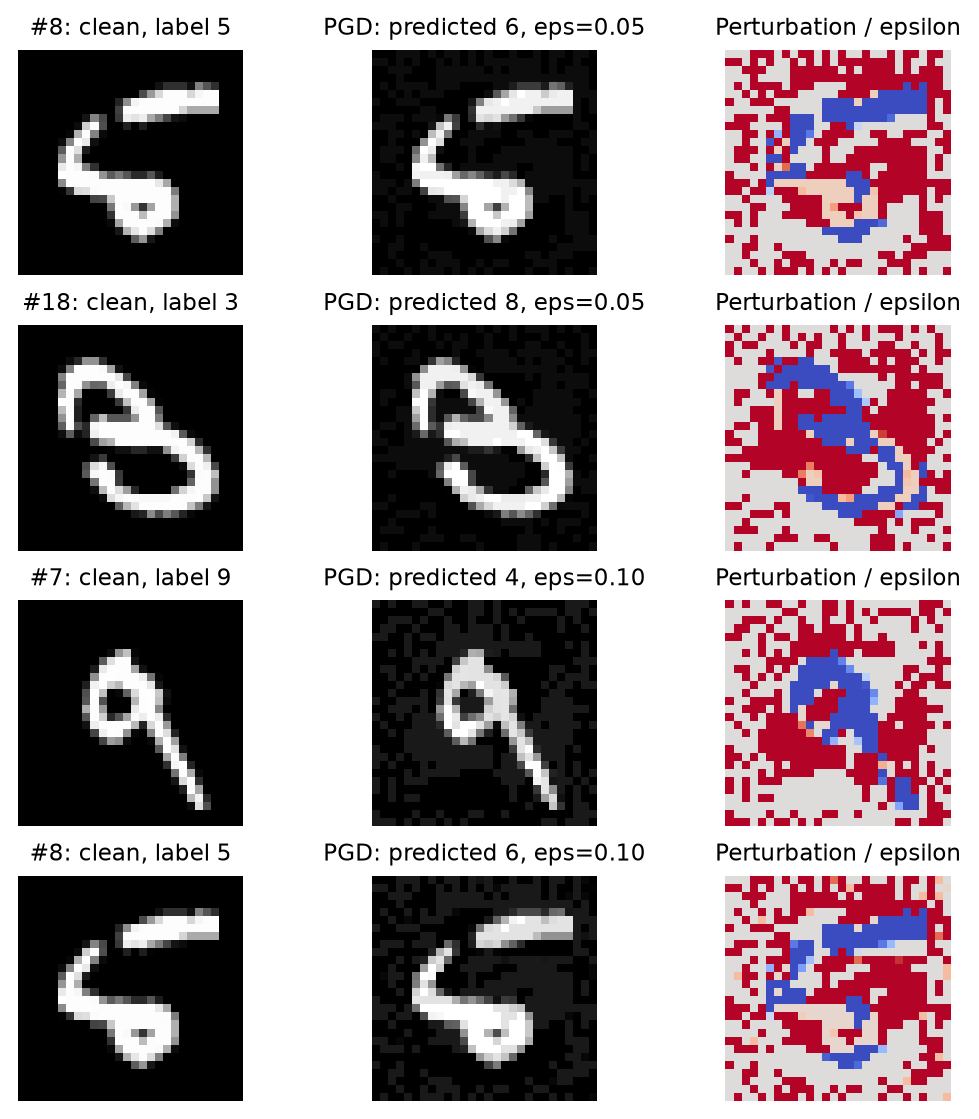

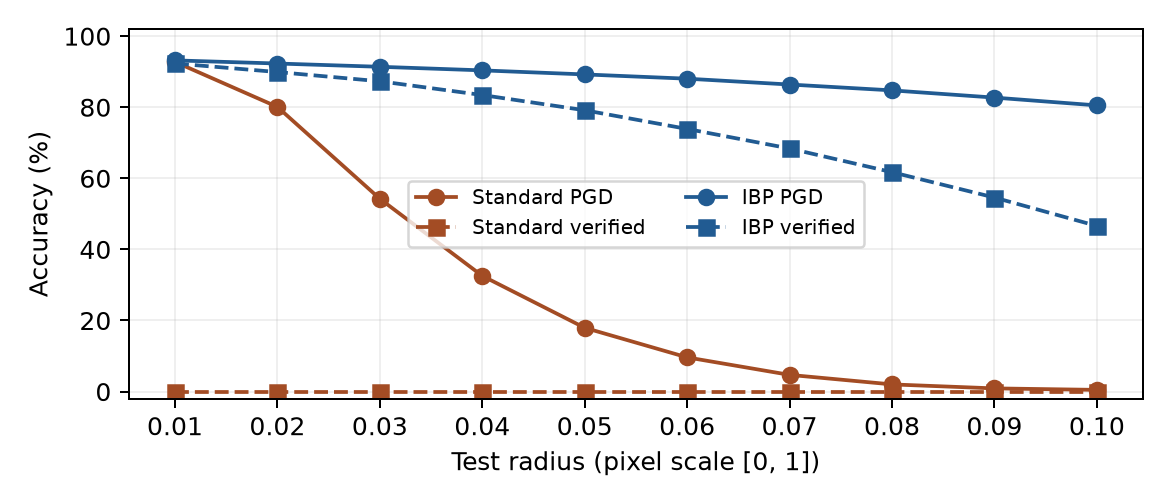

| Training | Clean | PGD at 0.10 | Total train time | Mean / epoch |
|---|---:|---:|---:|---:|
| Standard | 97.34% | 0.48% | 4.62 s | 0.23 s |
| IBP | 94.09% | 80.52% | 24.41 s | 1.22 s |

| Radius | Standard PGD | Standard verified | IBP PGD | IBP verified | IBP unresolved |
|---|---:|---:|---:|---:|---:|
| 0.01 | 92.76% | 0.00% | 93.18% | 92.32% | 86 |
| 0.02 | 80.08% | 0.00% | 92.30% | 89.90% | 240 |
| 0.03 | 54.24% | 0.00% | 91.38% | 87.30% | 408 |
| 0.04 | 32.55% | 0.00% | 90.37% | 83.43% | 694 |
| 0.05 | 17.94% | 0.00% | 89.23% | 79.15% | 1008 |
| 0.06 | 9.62% | 0.00% | 88.03% | 73.89% | 1414 |
| 0.07 | 4.70% | 0.00% | 86.39% | 68.39% | 1800 |
| 0.08 | 2.02% | 0.00% | 84.74% | 61.73% | 2301 |
| 0.09 | 0.90% | 0.00% | 82.71% | 54.59% | 2812 |
| 0.10 | 0.48% | 0.00% | 80.52% | 46.60% | 3392 |

| Test index (0-based) | Radius | True label | PGD prediction | Actual maximum change |
|---|---:|---:|---:|---:|
| 8 | 0.05 | 5 | 6 | 0.050000 |
| 18 | 0.05 | 3 | 8 | 0.050000 |
| 7 | 0.10 | 9 | 4 | 0.100000 |
| 8 | 0.10 | 5 | 6 | 0.100000 |


In [3]:
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
r=result
s,i=r['models']['standard'],r['models']['ibp']
assets=Path('results'); assets.mkdir(exist_ok=True)
examples=[]
for eps in [.05,.1]: examples.extend([e for e in r['examples'] if e['epsilon']==eps][:2])
fig,axes=plt.subplots(len(examples),3,figsize=(6.4,1.55*len(examples)),squeeze=False)
for row,e in enumerate(examples):
    clean=np.array(e['clean']).reshape(28,28);adv=np.array(e['adversarial']).reshape(28,28)
    axes[row,0].imshow(clean,cmap='gray',vmin=0,vmax=1)
    axes[row,1].imshow(adv,cmap='gray',vmin=0,vmax=1)
    axes[row,2].imshow((adv-clean)/e['epsilon'],cmap='coolwarm',vmin=-1,vmax=1)
    axes[row,0].set_title(f"#{e['index']}: clean, label {e['label']}",fontsize=9)
    axes[row,1].set_title(f"PGD: predicted {e['prediction']}, eps={e['epsilon']:.2f}",fontsize=9)
    axes[row,2].set_title('Perturbation / epsilon',fontsize=9)
    for ax in axes[row]:ax.axis('off')
fig.tight_layout(pad=.6);fig.savefig(assets/'problem1_adversarial.png',dpi=180,bbox_inches='tight');plt.show();plt.close(fig)
fig,ax=plt.subplots(figsize=(6.5,2.8))
for kind,label,color in [('standard','Standard','#a34c24'),('ibp','IBP','#215b92')]:
    rec=r['models'][kind];eps=[a['epsilon'] for a in rec['radii']]
    ax.plot(eps,[a['pgd_robust_count']/100 for a in rec['radii']],marker='o',color=color,label=label+' PGD')
    ax.plot(eps,[a['certified_count']/100 for a in rec['radii']],marker='s',linestyle='--',color=color,label=label+' verified')
ax.set(xlabel='Test radius (pixel scale [0, 1])',ylabel='Accuracy (%)',ylim=(-2,102));ax.set_xticks(eps);ax.grid(alpha=.2);ax.legend(fontsize=8,ncol=2)
fig.tight_layout();fig.savefig(assets/'problem1_accuracy.png',dpi=180);plt.show();plt.close(fig)
summary='| Training | Clean | PGD at 0.10 | Total train time | Mean / epoch |\n|---|---:|---:|---:|---:|\n'
for label,rec in [('Standard',s),('IBP',i)]:
    summary+=f"| {label} | {rec['clean_count']/100:.2f}% | {rec['radii'][-1]['pgd_robust_count']/100:.2f}% | {rec['seconds']:.2f} s | {sum(a['seconds'] for a in rec['epochs'])/20:.2f} s |\n"
table='| Radius | Standard PGD | Standard verified | IBP PGD | IBP verified | IBP unresolved |\n|---|---:|---:|---:|---:|---:|\n'
for a,b in zip(s['radii'],i['radii']):
    table+=f"| {a['epsilon']:.2f} | {a['pgd_robust_count']/100:.2f}% | {a['certified_count']/100:.2f}% | {b['pgd_robust_count']/100:.2f}% | {b['certified_count']/100:.2f}% | {b['unresolved_count']} |\n"
last=i['radii'][-1]
example_table='| Test index (0-based) | Radius | True label | PGD prediction | Actual maximum change |\n|---|---:|---:|---:|---:|\n'
for e in examples: example_table+=f"| {e['index']} | {e['epsilon']:.2f} | {e['label']} | {e['prediction']} | {e['linf']:.6f} |\n"

display(Markdown(summary+'\n'+table+'\n'+example_table))


## Analysis

At radius 0.10, IBP certifies 4660 images (46.60%), while PGD leaves 8052 images correct (80.52%). There are 3392 clean-correct unresolved images, a 33.92-point difference between these two accuracy estimates. The true robust accuracy lies between the verified and PGD accuracies, subject to the verifier's numerical precision. PGD finds attacks on 1357 initially correct IBP images at this radius.

Standard training gives no certificates even at radius 0.01, although its PGD accuracy there is 92.76%. This illustrates that naive box bounds can become very loose through multiple dense layers; zero verified accuracy does not mean every image can be attacked. IBP training explicitly penalizes these worst-case interval differences, making the same verifier substantially more useful. Both certification and PGD accuracy decrease as the radius increases. Retaining successful smaller-radius attacks ensures that the reported attack curve respects the nested threat sets.

